torch.utils
下面的data对象 用于数据集的下载和加载

In [ ]:
from llm_kernel.import_ import isImport
isImport(["torch","torchvision"])

# 或者直接用torch的内置version类
import torch
import torchvision
from torch.utils import data
print(torch.version.__version__)
print(torch.version.cuda)

torch版本： 2.14.1+cpu
torchvision版本： 0.29.1+cpu
2.14.1+cpu
None


FashionMNIST数据集由10个类别的图像组成， 每个类别由训练数据集（train dataset）中的6000张图像 和测试数据集（test dataset）中的1000张图像组成。 因此，训练集和测试集分别包含60000和10000张图像。 测试数据集不会用于训练，只用于评估模型性能。

In [4]:
# 通过ToTensor实例将图像数据从PIL类型变换成32位浮点数格式，
# 并除以255使得所有像素的数值均在0～1之间
trans = torchvision.transforms.ToTensor()
mnist_train = torchvision.datasets.FashionMNIST(
    root="data", train=True, transform=trans, download=True)
mnist_test = torchvision.datasets.FashionMNIST(
    root="data", train=False, transform=trans, download=True)

100%|██████████| 26.4M/26.4M [00:12<00:00, 2.05MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 172kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 2.75MB/s]
100%|██████████| 5.15k/5.15k [00:00<?, ?B/s]


In [ ]:
print(len(mnist_test),len(mnist_train))
print(mnist_train[0][0].shape) # torch.Size([1, 28, 28]),1表示通道数是1

10000 60000
torch.Size([1, 28, 28])


张量也能保存
使用torch.save和load
 FileLike 类指的是任何实现了文件接口的对象，也就是拥有 write() 方法（以及可选的 seek()、tell() 等方法）的对象。FILE_LIKE = Union[str, os.PathLike, BinaryIO, IO[bytes]]源码在 torch/serialization.py。


In [ ]:
import torch

x=torch.arange(6)
print(x)
torch.save(x,"data/x-file")


tensor([0, 1, 2, 3, 4, 5])
<class 'torch.Code'>


In [ ]:
a=torch.load('data/x-file')
print(a)

tensor([0, 1, 2, 3, 4, 5])


torch.utils的data类

DataLoader方法：用于加载数据，shuffle打乱顺序(默认关闭)，num_workers并发执行数(多个cpu核心并发读取磁盘)，
位置参数：xxx

In [14]:
X, y = next(iter(data.DataLoader(mnist_train, batch_size=18,num_workers=2)))
print(len(X),X[0][0].shape)

18 torch.Size([28, 28])


显示图像

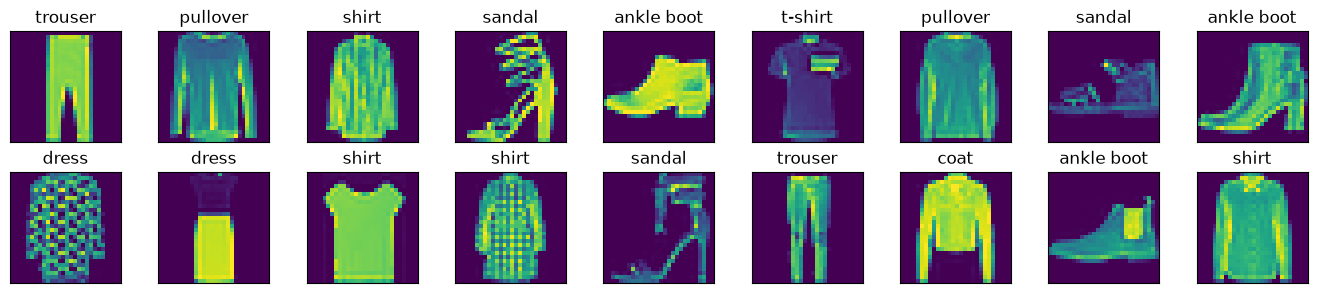

In [16]:
import matplotlib.pyplot as plt
import torch

def get_fashion_mnist_labels(labels):  #@save
    """返回Fashion-MNIST数据集的文本标签"""
    text_labels = ['t-shirt', 'trouser', 'pullover', 'dress', 'coat',
                   'sandal', 'shirt', 'sneaker', 'bag', 'ankle boot']
    return [text_labels[int(i)] for i in labels]

def show_images(imgs, num_rows, num_cols, titles=None, scale=1.5):
    """绘制图像列表"""
    figsize = (num_cols * scale, num_rows * scale)
    _, axes = plt.subplots(num_rows, num_cols, figsize=figsize)
    axes = axes.flatten()
    
    for i, (ax, img) in enumerate(zip(axes, imgs)):
        if torch.is_tensor(img):
            # 图片张量 → 转 numpy 显示
            ax.imshow(img.numpy())
        else:
            # PIL图片
            ax.imshow(img)
        
        ax.axes.get_xaxis().set_visible(False)
        ax.axes.get_yaxis().set_visible(False)
        
        if titles:
            ax.set_title(titles[i])
    
    plt.tight_layout()
    plt.show()  # 加上这行确保显示
    return axes

X, y = next(iter(data.DataLoader(mnist_train, batch_size=18,num_workers=2,shuffle=True)))
show_images(X.reshape(18, 28, 28), 2, 9, titles=get_fashion_mnist_labels(y));

整合数据下载加载生成迭代器


In [ ]:
import torchvision
import torch
from torch.utils import data
def load_data_fashion_mnist(batch_size, resize=None):  #@save
    """下载Fashion-MNIST数据集，然后将其加载到内存中"""
    trans = [torchvision.transforms.ToTensor()]
    if resize:
        trans.insert(0, torch.transforms.Resize(resize))
    trans = torchvision.transforms.Compose(trans)
    mnist_train = torchvision.datasets.FashionMNIST(
        root="data", train=True, transform=trans, download=True)
    mnist_test = torchvision.datasets.FashionMNIST(
        root="data", train=False, transform=trans, download=True)
    return (data.DataLoader(mnist_train, batch_size, shuffle=True,
                            num_workers=2),
            data.DataLoader(mnist_test, batch_size, shuffle=False,
                            num_workers=2))

train_iter,test_iter=load_data_fashion_mnist(10)


In [8]:
print(next(iter(train_iter)))

[tensor([[[[0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0078],
          [0.0000, 0.0000, 0.0000,  ..., 0.2588, 0.0000, 0.0118],
          ...,
          [0.0000, 0.7098, 0.8510,  ..., 0.0000, 0.0157, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0039, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000]]],


        [[[0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          ...,
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000]]],


        [[[0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  .